# General

All project work in IND320 will result in personal hand-ins and online apps.

### 1. Jupyter Notebook

A Jupyter Notebook run locally on your computer, later with access to online and local databases.

This will be your basic development and documentation platform.

#### Required content

- A brief description of AI usage.
- A 300–500-word log describing the compulsory work, including both Jupyter Notebook and Streamlit experience.
- Links to your public GitHub repository and Streamlit app for the compulsory work.

#### Documentation and submission

- Document headings should be clear and usable for navigation during development.
- All code blocks must include enough comments to be understandable and reproducible if someone inherits your project.
- All code blocks must be run before exporting to PDF so that messages and plots are shown.
- Add the `.ipynb` file to the GitHub repository containing your Streamlit project.

### 2. Streamlit App

A Streamlit app running at `https://[yourproject].streamlit.app/`.

- This will be an online version of the project, accessing data exported to CSV format and, later, an online database.
- The code must be hosted on GitHub.
- The code must include relevant comments from the Jupyter Notebook and additional comments regarding Streamlit usage.

#### Project Structure and Collaboration

- There are four parts in the project work, building on each other and resulting in a final portfolio and app to be presented at the end of the semester.
- Cooperation is applauded, and the use of AI tools is encouraged.

## Tasks

### GitHub and Streamlit.app accounts

- GitHub: https://github.com/danielytsan/IND320APP
- Steamlit: https://ind320app-s2bytfwvqxbzmwkxrm2aze.streamlit.app

# Presentation link

 Due to the video file being to large for github I have choosen to upload it to youtube. Use this link to access it:

https://youtu.be/NM3GvSNXUs8


## AI usage
AI has been used during development of the content provided for this app and Jupyter Notebook

The model I have been using is ChatGPT-6.1 Sol to:
- debugging and suggestion for code with error messages
- learning streamlit and different function
- learing to use api keys and how to format the files for it. Specially for how to use the token on Entso-e.
- help with using spark
- Used for helping with merge conflict
- some guidens on explaining the concept of the task

I have also started to explore suggestions agentic coding is giving me with copilot

# Jupyter Notebook

* Make a function for downloading Euro and USD currency exchange rates from the Norwegian Bank (NB) currency API and show that it works.

* Investigate possible timezone differences between Magasinstatistikk, ENTSO-E, OpenMeteo and NB and report your findings, plus solutions if needed.

* Using the River framework, make a function for SARIMAX or a lag-based Machine Learning with predictions of the coming months' fillings for a single region (according to Magasinstatistikk), letting relevant model parameters, length of history and horizon, and selection of data sources be inputs to the function.

    * Choose a reasonable time resolution for your input data so the function doesn't use an unreasonable amount of time while still performing well. Include findings in the report.

    * Test the function for various settings, report your findings (how you tested and your experiences) and let the best solution be the default setting when used in Streamlit.

* Include the sketch mentioned in "Streamlit app, refactoring -> Structure and navigation" below.

In [48]:
#importing libraris
from river import linear_model, optim, preprocessing, tree
import pandas as pd
import re
import json
import requests
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt

In [14]:
def exchange_rates(observations = 60):
    url = "https://data.norges-bank.no/api/data/EXR/B.USD+EUR.NOK.SP?format=sdmx-json&lastNObservations=60&locale=no"
    response = requests.get(
        url,
        params = {
            "format": "sdmx-json",
            "lastNObservation": observations,
            "locale": "no",
        },
        timeout = 30,
    )
    response.raise_for_status()
    payload = response.json()
    data = payload.get("data", payload)

    #reading currency labels and dates
    dimensions = data["structure"]["dimensions"]
    currency_position = next(
        i for i, dimension in enumerate(dimensions["series"])
        if dimension["id"] == "BASE_CUR"
    )
    currencies = dimensions["series"][currency_position]["values"]
    dates = dimensions["observation"][0]["values"]

    #match each observation to its currency and date
    records = []
    for key, series in data["dataSets"][0]["series"].items():
        currency_index = int(key.split(":")[currency_position])
        currency = currencies[currency_index]["id"]

        for date_index, values in series["observations"].items():
            records.append({
                "Date": dates[int(date_index)]["id"],
                "Currency": currency,
                "Rate": values[0],
            })

    #creating table with dates as rows and currencies as column
    rates = pd.DataFrame(records)
    rates["Date"] = pd.to_datetime(rates["Date"])
    rates["Rate"] = pd.to_numeric(rates["Rate"], errors = "raise")
    rates = rates.pivot(index = "Date", columns = "Currency", values = "Rate")
    rates.columns.name = None

    return rates.sort_index()[["EUR", "USD"]]

#running the function
rates = exchange_rates()
assert rates.count().to_dict() == {"EUR": 60, "USD": 60}
assert (rates > 0).all().all()
assert rates.index.is_unique and rates.index.is_monotonic_increasing
print(rates.tail().to_string(float_format = "{:.4f}".format))


               EUR    USD
Date                     
2026-11-18 10.6045 9.6686
2026-11-19 10.6475 9.6866
2026-11-20 10.7180 9.7525
2026-11-23 10.7285 9.8076
2026-11-24 10.7350 9.7920


* Investigate possible timezone differences between Magasinstatistikk, ENTSO-E, OpenMeteo and NB and report your findings, plus solutions if needed.

    In this part i will be exploring the timezones form all of the api to make sure that all of the are on the same page

Magasinstatistikk

In [15]:
magasinstatistikk_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(magasinstatistikk_url, timeout = 30)
response.raise_for_status()
reservoir = pd.DataFrame(response.json())

#inspecting the original dates before converting
display(reservoir["dato_Id"].head())


0    2020-11-15
1    2011-08-28
2    1998-07-05
3    2011-03-27
4    2017-11-05
Name: dato_Id, dtype: object

Enstoe

In [16]:
#making a path to the secrets file and reading it into a dictionary
secrets = {}

with open("../.streamlit/secrets.toml", "r") as file:
    for line in file:
        line = line.strip()

        #Skip empty lines and comments
        if not line or line.startswith("#"):
            continue

        name, value = line.split("=", 1)
        secrets[name.strip()] = value.strip()

#configuring Entsoe client with API key from secrets file
from entsoe import EntsoePandasClient
from entsoe.exceptions import NoMatchingDataError

client = EntsoePandasClient(api_key=secrets["entsoe_api_token"])

start = pd.Timestamp("2024-10-27", tz="Europe/Oslo")
end = pd.Timestamp("2024-10-28", tz="Europe/Oslo")

flows = client.query_crossborder_flows(
    country_code_from = "NO",
    country_code_to = "SE",
    start = start,
    end = end
)

print("returned timezone:", flows.index.tz)

#compare the same observation in UTC and Norwegian time
comparison = pd.DataFrame({
    "UTC": flows.tz_convert("UTC"),
    "Norwegian": flows.index.tz_convert("Europe/Oslo"),
    "Flow MW": flows.to_numpy(),
})

display(comparison.head())

returned timezone: Europe/Oslo


,UTC,Norwegian,Flow MW
2024-10-26 22:00:00+00:00,7.94,2024-10-27 00:00:00+02:00,7.94
2024-10-26 23:00:00+00:00,0.00,2024-10-27 01:00:00+02:00,0.00
2024-10-27 00:00:00+00:00,0.00,2024-10-27 02:00:00+02:00,0.00
2024-10-27 01:00:00+00:00,0.00,2024-10-27 02:00:00+01:00,0.00
2024-10-27 02:00:00+00:00,0.00,2024-10-27 03:00:00+01:00,0.00


Open meteo

In [17]:
meteo_url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 59.91, #agentic codeing
    "longitude": 10.75, #agentic codeing
    "start_date": "2024-10-26",
    "end_date": "2024-10-28",
    "hourly": "temperature_2m,precipitation",
    "models": "era5",
    "timezone": "GMT",
}

response = requests.get(meteo_url, params = params, timeout = 30)
response.raise_for_status()
weather = pd.DataFrame(response.json()["hourly"])

#change the requested gmt timestamps as utc
weather["time"] = pd.to_datetime(weather["time"], utc = True)
comparison = pd.DataFrame({
    "UTC": weather["time"],
    "Norwegian time": weather["time"].dt.tz_convert("Europe/Oslo"),
})

#selecting the dat when the clocks change from summer to winter time
start = pd.Timestamp("2024-10-27", tz = "Europe/Oslo")
end = pd.Timestamp("2024-10-28", tz = "Europe/Oslo")

day = comparison.loc[(comparison["Norwegian time"] >= start) & (comparison["Norwegian time"] < end)]
display(day.head())
print("Hours in Norwegian time:", len(day))

,UTC,Norwegian time
22,2024-10-26 22:00:00+00:00,2024-10-27 00:00:00+02:00
23,2024-10-26 23:00:00+00:00,2024-10-27 01:00:00+02:00
24,2024-10-27 00:00:00+00:00,2024-10-27 02:00:00+02:00
25,2024-10-27 01:00:00+00:00,2024-10-27 02:00:00+01:00
26,2024-10-27 02:00:00+00:00,2024-10-27 03:00:00+01:00


Hours in Norwegian time: 25


Norges bank

In [18]:
rates = exchange_rates(observations = 5)

display(rates.head())
print("Index type", rates.index.dtype)
print("Timezone:", rates.index.tz)

,EUR,USD
Date,,
2026-09-02,10.8090,9.3358
2026-09-03,10.8063,9.3037
2026-09-04,10.8035,9.2957
2026-09-07,10.7740,9.2703
2026-09-08,10.7450,9.2518


Index type datetime64[ns]
Timezone: None


Based on my finding I found out that:

* Magisinstatistikk does not refer to a spesific timezone.

* Entsoe we uses tz_convert() to show the same observation in UTC and Europe/Oslo.

* Open meteo uses GTM as timezone, we therefor convert it with datetime to UTC.

* Norges Bank is the same as magasinstatistikk that does not refer to e spesific timezone.

* Using the River framework, make a function for SARIMAX or a lag-based Machine Learning with predictions of the coming months' fillings for a single region (according to Magasinstatistikk), letting relevant model parameters, length of history and horizon, and selection of data sources be inputs to the function.

    * Choose a reasonable time resolution for your input data so the function doesn't use an unreasonable amount of time while still performing well. Include findings in the report.

    * Test the function for various settings, report your findings (how you tested and your experiences) and let the best solution be the default setting when used in Streamlit.

In [19]:
#preparing data and define the forecasting function
def reservoir_data(reservoir, region = "NO3"):
    #NVE stores eletricity regions as EL
    match = re.fullmatch(r"(NO|EL|VASS)\s*([0-5])", region.upper().strip())
    area = match.group(1)
    number = int(match.group(2))

    if area == "NO" and number > 0:
        area = "EL"

    valid_region = (
        (area == "EL" and 1 <= number <= 5) or
        (area == "VASS" and 1 <= number <= 3) or
        (area == "NO" and number == 0)
    )

    #renaming the colums
    data = reservoir.rename(columns = {
        "dato_Id": "Date",
        "omrType": "Area",
        "omrnr": "Area number",
        "fyllingsgrad": "Filling level",
    }).copy()

    if "Fill level (%)" in data:
        data["fill_pct"] = pd.to_numeric(data["Fill level (%)"], errors = "raise",)
    else:
        data["fill_pct"] = pd.to_numeric(data["Filling level"], errors = "raise") * 100

    selected = data.loc[
        data["Area"].eq(area) & data["Area number"].eq(number),
        ["Date", "fill_pct"],
    ].copy()

    selected["Date"] = pd.to_datetime(selected["Date"])
    selected["Date"] = selected["Date"].dt.normalize()  #remove the time component
    selected = selected.drop_duplicates()

    #missing weeks becom na and are checked before forecasting
    return selected.set_index("Date").sort_index().asfreq("W-SUN")
    


In [20]:
#defining the river model
def make_regressor(model, learning_rate, l2):
    if model == "river_linear":
        return (preprocessing.StandardScaler() | linear_model.LinearRegression(
            optimizer = optim.SGD(learning_rate),
            intercept_lr = learning_rate,
            l2 = l2,
            clip_gradient = 1.0,
        ))

    return tree.HoeffdingTreeRegressor(
        grace_period = 25,
        leaf_prediction = "mean",
    )

In [36]:
#making a forecasting function
def forecast_filling(
        reservoir,
        region = "NO3",
        history_years = 5,
        horizon_weeks = 12,
        lag_count = 4,
        model = "river_linear",
        learning_rate = 0.01,
        l2 = 0.001,
        source = ("reservoir",),
        source_data = None,
        cutoff = None,
):
    #forcast weekly filling for one region
    limits = [
        ("history_years", history_years, 2, 30),
        ("horizon_weeks", horizon_weeks, 1, 52),
        ("lag_count", lag_count, 1, 52),
    ]

    allowed_models = {
        "river_linear",
        "river_tree",
        "last_value",
        "seasonal_naive",
    }

    #convert the selected source name to a consistent representation
    source = tuple(source)

    #prepareing one chronological, weekly reservoir series
    data = reservoir_data(reservoir, region = region)
    if cutoff is not None:
        data = data.loc[:pd.Timestamp(cutoff)].copy()
    origin = data.index[-1] #forcast orgin is the last knows reporting date@
    history_start = origin - pd.DateOffset(years = history_years)
    data = data.loc[history_start:].copy()
    target = data["fill_pct"]

    #createing one sundag date for each future prediction
    future_date = pd.date_range(
        origin + pd.DateOffset(weeks = 1),
        periods = horizon_weeks,
        freq = "W-SUN",
    )

    #seasonal baseline
    seasonal = target.iloc[-52:].to_numpy()[:horizon_weeks]
    forecast = pd.DataFrame(
        {"seasonal_naive": seasonal},
        index = future_date,
    )
    forecast.index.name = "Date"

    if model == "last_value":
        forecast["prediction"] = float(target.iloc[-1])
    elif model == "seasonal_naive":
        forecast["prediction"] = forecast["seasonal_naive"]
    else:
        #creating laged predictors for each selected column
        features = pd.DataFrame({
            f"{column}_lag_{lag}": data[column].shift(lag)
            for column in data.columns
            for lag in range(lag_count)
        })

        #inlcudeing the difference from 52 week earlier
        features["fill_year_change"] = target.diff(52)

        predictions = []

        #training a model for each horizon
        for horizon in range(1, horizon_weeks + 1):
            x = features.copy()

            #determine which future week each training row predicts
            target_dates = x.index + pd.Timedelta(weeks = horizon)
            phase = 2 * np.pi * target_dates.dayofyear / 365.25
            x["season_sin"] = np.sin(phase)
            x["season_cos"] = np.cos(phase)

            #devision by 100 scales a 10% differens to 0.1 for the regression
            residual = (target.shift(-horizon) - target.shift(52 - horizon)) / 100

            #remocing rows without sufficient lag history
            training = x.join(residual.rename("response")).dropna()
            origin_features = x.loc[[origin]]

            #adding a new learner for this horizon
            learner = make_regressor(model, learning_rate, l2)
            feature_names = list(x.columns)

            #riiver learns one observation at a time, so it needs to be sorted for training
            for row in training.itertuples(index = False, name = None):
                inputs = dict(zip(feature_names, row[:-1]))
                response_value = row[-1]
                learner.learn_one(inputs, response_value)

            origin_features = x.loc[origin]

            #prediction of the annual corretion for this future week
            correction = learner.predict_one(origin_features.to_dict())
            prediction = seasonal[horizon - 1] + correction * 100
            predictions.append(float(np.clip(prediction, 0, 100)))

        forecast["prediction"] = predictions

    #store conext with the returned tabel
    forecast.attrs["region"] = region
    forecast.attrs["origin"] = str(origin.date())
    forecast.attrs["model"] = model
    forecast.attrs["source"] = list(source)

    return forecast[["prediction", "seasonal_naive"]]
    


In [37]:
#backtest model
def backtest_models(
        reservoir,
        configurations,
        cutoffs,
        region = "NO3",
        horizons = (4, 13, 26),
        source_data = None,
):
    actual = reservoir_data(reservoir, region = region)["fill_pct"]
    records = []

    for configuration in configurations:
        settings = configuration.copy()
        name = settings.pop("name")
        errors_by_horizon = {horizon: [] for horizon in horizons}
        runtimes = []

        for cutoff in cutoffs:
            started = perf_counter()

            #forcasting the longest horizon once
            forecast = forecast_filling(
                reservoir,
                region = region,
                cutoff = cutoff,
                horizon_weeks = max(horizons),
                source_data = source_data,
                **settings,
            )

            runtimes.append(perf_counter()- started)
            #retreving furture measrue after forecasting and using it for evaluation
            truth = actual.reindex(forecast.index)
            errors = forecast["prediction"] - truth

            for horizon in horizons:
                errors_by_horizon[horizon].extend(errors.iloc[:horizon].tolist())

        #combine errors from cutoff before calculating the scores    
        for horizon in horizons:
            errors = np.asarray(errors_by_horizon[horizon], dtype = float,)
            records.append({
                "name": name,
                "model": settings["model"],
                "horizon_weeks": horizon,
                "mae_pp": np.mean(np.abs(errors)), 
                "rmse_pp": np.sqrt(np.mean(errors ** 2)), #gives larger individual errors more weight
                "seconds_max_horizon": np.mean(runtimes), #average runtime for the longest horizon
            })

    return pd.DataFrame(records)

In [51]:
#comparing different settings
weekly = reservoir_data(reservoir, region = "NO3")

#largest setting kan use 10 years of history
dates = weekly.index

#validation origin is 79 observations from the end with 26 weeks apart
validation_cutoffs = [dates[-131], dates[-105], dates[-79],]
test_cutoffs = [dates[-53], dates[-27],]

#simple baselines show if the river models add predictive value
baselines = [
    {
        "name": "Last observed value",
        "model": "last_value",
        "history_years": 5,
    },
    {
        "name": "Same week 52 weeks ago",
        "model": "seasonal_naive",
        "history_years": 5,
    }
]

candidates = []

#comparing 3 history lengths, 2 lag and 2 learning rates, giving 12 linear model config
for years in (3, 5,10):
    for lags in (4, 13):
        for rate in (0.005, 0.02):
            candidates.append({
                "name": f"Linear {years}, {lags} lags, rate {rate}",
                "model": "river_linear",
                "history_years": years,
                "lag_count": lags,
                "learning_rate": rate,
                "l2": 0.001,
            })

#add two tree config for comparison
for lags in (4, 13):
    candidates.append({
        "name": f"Tree {lags} lags",
        "model": "river_tree",
        "history_years": 5,
        "lag_count": lags,
    })

configurations = baselines + candidates

#evaluate every config at the same historical origins
validation_results = backtest_models(
    reservoir,
    configurations,
    validation_cutoffs,
    region = "NO3",
)

#grouping by horizion and displaying the lowest MAE first
display(validation_results.sort_values(["horizon_weeks", "mae_pp"]).reset_index(drop = True).head())


,name,model,horizon_weeks,mae_pp,rmse_pp,seconds_max_horizon
0,"Linear 3, 4 lags, rate 0.02",river_linear,4,3.599616,4.601694,0.111738
1,"Linear 10, 4 lags, rate 0.02",river_linear,4,3.607481,5.233870,0.278771
2,"Linear 10, 13 lags, rate 0.005",river_linear,4,3.793887,5.113269,0.439919
3,"Linear 10, 4 lags, rate 0.005",river_linear,4,4.114100,4.821998,0.288081
4,"Linear 5, 4 lags, rate 0.02",river_linear,4,4.784745,7.131217,0.187658


In [39]:
#select the best river setting and evaluating the final year
eligible = validation_results.loc[
    validation_results["model"].isin(["river_linear", "river_tree"])
    & validation_results["horizon_weeks"].eq(13)
]

best = eligible.sort_values([
    "mae_pp",
    "rmse_pp",
    "seconds_max_horizon",
]).iloc[0]

best_config = next(
    configuration.copy()
    for configuration in candidates
    if configuration["name"] == best["name"]
)

best_name = best_config.pop("name")
print("selected river config", best_name)
print("validation MAE:", round(best["mae_pp"], 2), "percentage points",)

selected river config Linear 3, 4 lags, rate 0.02
validation MAE: 7.38 percentage points


In [40]:
#evalueating on the final year
test_config = baselines + [{"name": "selected river model", **best_config,}]
test_results = backtest_models(reservoir, test_config, test_cutoffs, region = "NO3")
display(test_results.sort_values(["horizon_weeks", "mae_pp"]).reset_index(drop = True))

,name,model,horizon_weeks,mae_pp,rmse_pp,seconds_max_horizon
0,selected river model,river_linear,4,3.073168,4.680161,0.097716
1,Last observed value,last_value,4,11.074379,12.836987,0.019607
2,Same week 52 weeks ago,seasonal_naive,4,15.941553,17.567032,0.012485
3,selected river model,river_linear,13,6.524163,9.232764,0.097716
4,Same week 52 weeks ago,seasonal_naive,13,22.364219,23.744553,0.012485
5,Last observed value,last_value,13,23.539191,26.245457,0.019607
6,selected river model,river_linear,26,18.547117,23.634462,0.097716
7,Same week 52 weeks ago,seasonal_naive,26,23.322316,24.244761,0.012485
8,Last observed value,last_value,26,36.365773,40.133181,0.019607


In [41]:
#saving the validation with best score so it can be used in streamlit later
defaults = {
    "status": "validated",
    "region_validated": "NO3",
    "configuration_name": best_name,
    "horizon_weeks": 13,
    "validation_mae_pp": float(best["mae_pp"]),
    "settings": best_config,
}

defaults_path = Path("../data/forecast_default.json")
defaults_path.write_text(json.dumps(defaults, indent = 2), encoding = "utf-8")

313

In [43]:
#making the forcasting for the next 13 weeks
forecast = forecast_filling(reservoir, region = "NO3", horizon_weeks = 13, **best_config)

#cheking the structure
assert len(forecast) == 13
assert forecast.index.is_unique
assert np.isfinite(forecast["prediction"]).all()
assert forecast["prediction"].between(0, 100).all()
display(forecast)

,prediction,seasonal_naive
Date,,
2026-11-29,62.298409,82.406926
2026-12-06,58.766142,79.539526
2026-12-13,56.260012,77.400560
2026-12-20,55.155776,76.640946
2026-12-27,51.982633,73.751426
2027-01-03,47.514383,69.741434
2027-01-10,42.547275,65.261130
2027-01-17,37.694173,60.781340
2027-01-24,32.036828,55.780816


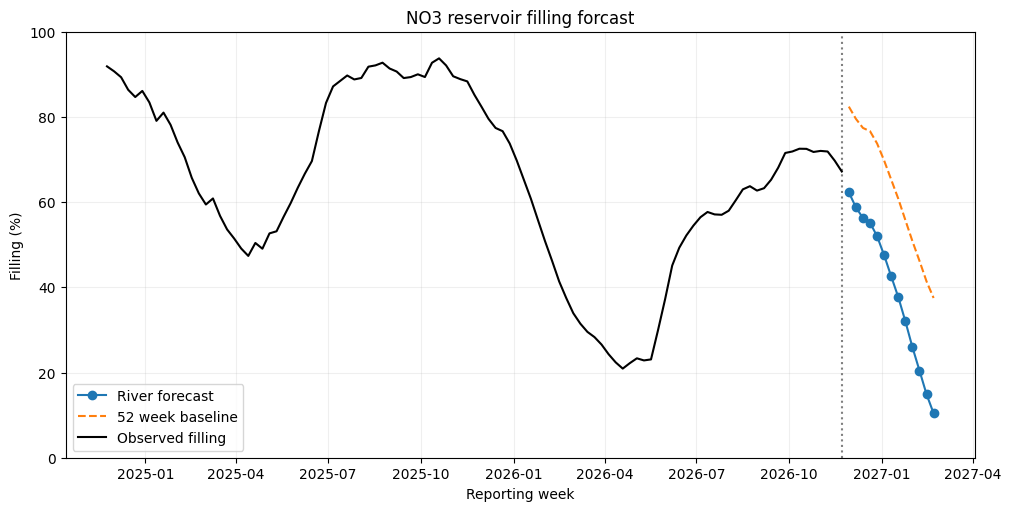

In [50]:
history = reservoir_data(reservoir, region = "NO3",)["fill_pct"]
origin = pd.Timestamp(forecast.attrs["origin"])
start = origin - pd.DateOffset(years = 2)
recent_history = history.loc[start:origin]

fig, ax = plt.subplots(figsize = (10, 5), layout = "constrained",)
ax.plot(forecast.index, forecast["prediction"], marker = "o", label = "River forecast")
#seasonal baseline beside the fitted model
ax.plot(forecast.index, forecast["seasonal_naive"], linestyle = "--", label = "52 week baseline")
#marking the boundary between observed history and future prediction
ax.axvline(origin, color = "grey", linestyle = ":")
ax.set(title = "NO3 reservoir filling forcast", 
       xlabel = "Reporting week", 
       ylabel = "Filling (%)",
       ylim = (0, 100),)
ax.grid(alpha = 0.2)
ax.plot(recent_history.index, 
        recent_history, 
        color = "black",
        label = "Observed filling",)
ax.legend()
plt.show()

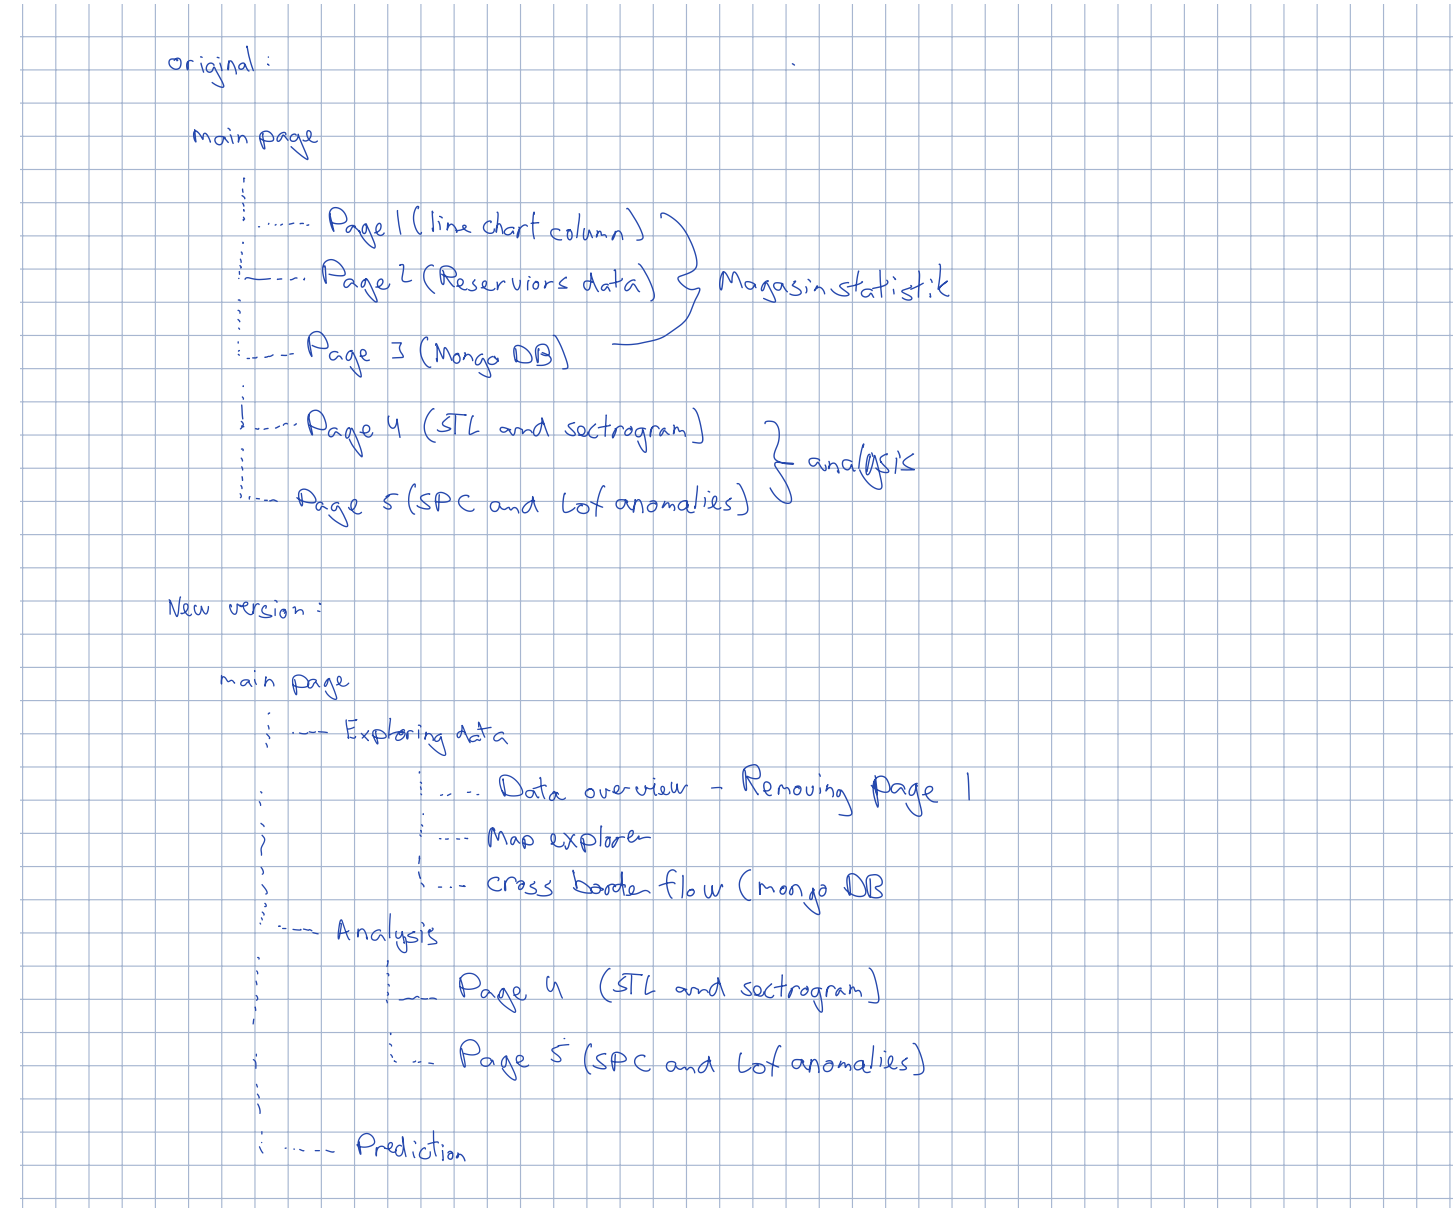

In [66]:
from IPython.display import Image
Image("../data/sketch.png", width = 800, height = 600)
